# Experiment 2: Which ControlNet Keeps an Interior Best? Canny vs MLSD vs Depth

In Experiment 1 [interior_render_preservation.ipynb](https://github.com/Mervecaliskann/interior-render-preservation/blob/main/interior_render_preservation.ipynb) I used only **Canny** edges. Canny finds *every* edge, including leaves, trees and textures. For architecture, two other ControlNets are often used:

| Control type | What the model gets | Idea |
|---|---|---|
| **Canny** | All edges in the image | Baseline from Experiment 1 |
| **MLSD** | Only **straight lines** (walls, windows, doors, furniture edges) | Made for architecture; ignores plants and noise |
| **Depth** | A depth map (near = bright, far = dark) | Keeps the 3D layout of the room |

All three run in the same setup as Method B: img2img with the original photo, `strength=0.6`, same prompt, same seed.

**Measured:** SSIM, edge recall, straight-line recall, mean ΔE, CLIP gain, **seconds per image** and **peak GPU memory**.

Part 2 tests simple speed settings, because the job of a render tool is also to be fast and cheap.

## 1. Setup

In [1]:
!pip uninstall -y torchao
!pip install -q diffusers transformers accelerate opencv-python

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## 2. Check the GPU (must print True and Tesla T4)

In [2]:
import torch
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0))

2.11.0+cu130 True Tesla T4


## 3. Upload the same room images as in Experiment 1

In [3]:
from google.colab import files
uploaded = files.upload()
images = list(uploaded)
print(images)

Saving living-room.jpg to living-room.jpg
Saving open-plan.jpg to open-plan.jpg
Saving room.jpg to room.jpg
['living-room.jpg', 'open-plan.jpg', 'room.jpg']


## 4. Load the models (run once)
One Stable Diffusion model, three ControlNets. The three pipelines **share** the same Stable Diffusion weights, so memory is used only once. Only the ControlNet changes.

In [4]:
import time, cv2, numpy as np, pandas as pd
from PIL import Image
from diffusers import StableDiffusionControlNetImg2ImgPipeline, ControlNetModel

dtype = torch.float16
cn = {
    "Canny": ControlNetModel.from_pretrained("lllyasviel/sd-controlnet-canny", torch_dtype=dtype),
    "MLSD":  ControlNetModel.from_pretrained("lllyasviel/sd-controlnet-mlsd",  torch_dtype=dtype),
    "Depth": ControlNetModel.from_pretrained("lllyasviel/sd-controlnet-depth", torch_dtype=dtype),
}
base = StableDiffusionControlNetImg2ImgPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    controlnet=cn["Canny"], torch_dtype=dtype).to("cuda")

pipes = {name: StableDiffusionControlNetImg2ImgPipeline(**{**base.components, "controlnet": m.to("cuda")})
         for name, m in cn.items()}

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

## 5. Control images
- **Canny:** OpenCV edge detector (as before).
- **MLSD:** straight line segments found with OpenCV's Line Segment Detector. Short lines (under 20 px) are dropped, so leaves and textures disappear.
- **Depth:** a small depth model (Depth Anything V2) estimates how far each pixel is.

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

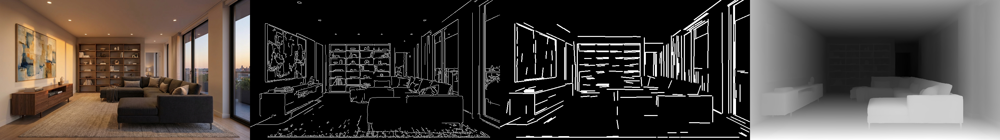

In [5]:
from transformers import pipeline as hf_pipeline

prompt = "photorealistic interior render, light oak wooden floor, white walls, natural daylight"
negative = "blurry, distorted, low quality, deformed"
W, H = 768, 432
SEED, STRENGTH, STEPS = 42, 0.6, 25

depth_estimator = hf_pipeline("depth-estimation", model="depth-anything/Depth-Anything-V2-Small-hf", device=0)
lsd = cv2.createLineSegmentDetector()

def load_room(name):
    return Image.open(name).convert("RGB").resize((W, H))

def to_rgb(gray):
    return Image.fromarray(np.stack([gray] * 3, axis=-1))

def canny_map(room):
    return to_rgb(cv2.Canny(np.array(room), 100, 200))

def line_map(room, min_len=20):
    gray = cv2.cvtColor(np.array(room), cv2.COLOR_RGB2GRAY)
    lines = lsd.detect(gray)[0]
    canvas = np.zeros_like(gray)
    if lines is not None:
        for x1, y1, x2, y2 in lines.reshape(-1, 4):
            if np.hypot(x2 - x1, y2 - y1) >= min_len:
                cv2.line(canvas, (int(x1), int(y1)), (int(x2), int(y2)), 255, 2)
    return to_rgb(canvas)

def depth_map(room):
    d = depth_estimator(room)["depth"].resize((W, H))
    return d.convert("RGB")

control_makers = {"Canny": canny_map, "MLSD": line_map, "Depth": depth_map}

def show_row(imgs):
    row = Image.new("RGB", (W * len(imgs), H))
    for i, im in enumerate(imgs):
        row.paste(im.resize((W, H)), (i * W, 0))
    display(row)

# look at the three control images for the first room
room = load_room(images[0])
show_row([room] + [make(room) for make in control_makers.values()])  # original | Canny | MLSD | Depth

## 6. Metrics
Same metrics as Experiment 1, plus:
- **Straight-line recall:** share of the original *straight* lines that are still in the render. Edge recall uses Canny, so it slightly favors the Canny method; this metric is fairer for MLSD.
- **Seconds per image** and **peak GPU memory (GB)**.

In [6]:
from skimage.metrics import structural_similarity as ssim
from skimage.color import rgb2lab, deltaE_ciede2000
from transformers import CLIPModel, CLIPProcessor

def recall(orig_mask, rend_mask):
    rend_mask = cv2.dilate(rend_mask.astype(np.uint8), np.ones((5, 5), np.uint8)) > 0
    return (orig_mask & rend_mask).sum() / max(orig_mask.sum(), 1)

def edge_recall(orig, rend):
    return recall(cv2.Canny(orig, 100, 200) > 0, cv2.Canny(rend, 100, 200) > 0)

def line_recall(orig, rend):
    return recall(np.array(line_map(Image.fromarray(orig)))[..., 0] > 0,
                  np.array(line_map(Image.fromarray(rend)))[..., 0] > 0)

def mean_delta_e(orig, rend):
    return deltaE_ciede2000(rgb2lab(orig), rgb2lab(rend)).mean()

def gray(a):
    return cv2.cvtColor(a, cv2.COLOR_RGB2GRAY)

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to("cuda")
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
def clip_score(img, text="a room with a light oak wooden floor"):
    inputs = clip_proc(text=[text], images=img, return_tensors="pt", padding=True).to("cuda")
    with torch.no_grad():
        out = clip(**inputs)
    return float((out.image_embeds @ out.text_embeds.T).item() * 100)

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

## 7. Run the comparison
For every room and every control type: build the control image, generate the render, time it, and measure it.
Shown per room: **original | Canny | MLSD | Depth**.

  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

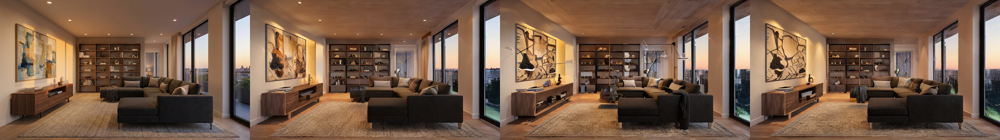

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

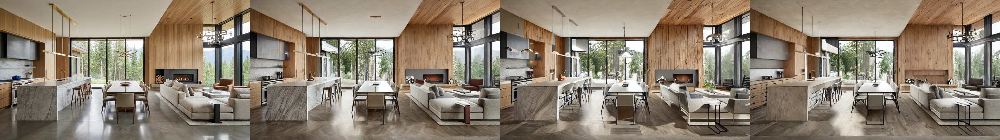

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

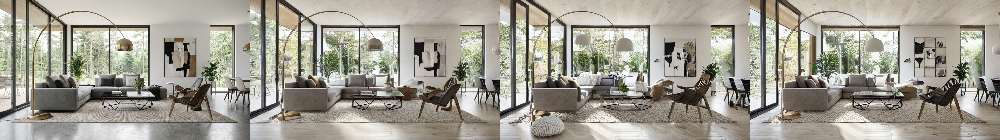

,room,control,SSIM ↑,Edge recall ↑,Line recall ↑,Mean ΔE ↓,CLIP gain ↑,Sec/image,Peak GPU GB
0,1,Canny,0.631,0.929,0.779,7.794,1.128,5.136,6.53
1,1,MLSD,0.551,0.841,0.738,8.890,2.591,5.311,6.53
2,1,Depth,0.584,0.819,0.692,7.985,2.047,5.352,6.53
3,2,Canny,0.534,0.932,0.753,9.382,3.464,5.465,6.53
4,2,MLSD,0.421,0.849,0.726,11.642,1.343,5.460,6.53
5,2,Depth,0.452,0.815,0.671,10.795,2.660,5.520,6.53
6,3,Canny,0.532,0.957,0.824,9.655,-0.046,5.647,6.53
7,3,MLSD,0.423,0.872,0.683,11.821,2.420,5.770,6.53
8,3,Depth,0.439,0.891,0.732,11.320,1.006,5.950,6.53


,SSIM ↑,Edge recall ↑,Line recall ↑,Mean ΔE ↓,CLIP gain ↑,Sec/image,Peak GPU GB
control,,,,,,,
Canny,0.566,0.939,0.785,8.944,1.515,5.416,6.53
Depth,0.492,0.842,0.698,10.033,1.904,5.607,6.53
MLSD,0.465,0.854,0.716,10.784,2.118,5.513,6.53


In [7]:
def generate(pipe, room, control, steps=STEPS):
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    out = pipe(prompt, negative_prompt=negative, image=room, control_image=control,
               strength=STRENGTH, num_inference_steps=steps,
               generator=torch.manual_seed(SEED)).images[0]
    torch.cuda.synchronize()
    return out, time.perf_counter() - t0, torch.cuda.max_memory_allocated() / 1e9

# warm-up run (the first run on a GPU is always slower)
_ = generate(pipes["Canny"], load_room(images[0]), canny_map(load_room(images[0])), steps=5)

rows = []
for n, name in enumerate(images, start=1):
    room = load_room(name)
    orig = np.array(room)
    renders = []
    for method, make in control_makers.items():
        control = make(room)
        out, sec, mem = generate(pipes[method], room, control)
        out.save(f"exp2_{method.lower()}_{n}.jpg", quality=90)
        renders.append(out)
        rend = np.array(out)
        rows.append({"room": n, "control": method,
                     "SSIM ↑": ssim(gray(orig), gray(rend)),
                     "Edge recall ↑": edge_recall(orig, rend),
                     "Line recall ↑": line_recall(orig, rend),
                     "Mean ΔE ↓": mean_delta_e(orig, rend),
                     "CLIP gain ↑": clip_score(out) - clip_score(room),
                     "Sec/image": sec, "Peak GPU GB": mem})
    show_row([room] + renders)

    grid = Image.new("RGB", (W * 4, H))
    for i, im in enumerate([room] + renders):
        grid.paste(im, (i * W, 0))
    grid.save(f"exp2_comparison_{n}.jpg", quality=90)

df = pd.DataFrame(rows)
display(df.round(3))
summary = df.groupby("control").mean(numeric_only=True).drop(columns="room").round(3)
display(summary)

What I saw.

- Canny: kept the room best. The marble island, the fireplace and the chairs stayed. It applied the prompt the least (lowest CLIP gain).
- MLSD: invented objects where there were no straight lines: a floor lamp and a side table in the living room, a pouf in another room. A chair changed its design, the marble island turned into light wood and the brass lamp shade became white. MLSD gives only straight lines, so curved objects like the arc lamp are missing from the map, and the model fills the gaps itself.
- Depth: kept the overall layout but lost details. The fireplace disappeared, the island turned into wood, and a painting became a grid of small frames. A depth map shows where a wall is, not what is on it.

Result. Against my expectation, Canny was the best at keeping the design on every metric (SSIM 0.566, edge recall 0.939, line recall 0.785, mean ΔE 8.9), even on straight-line recall, where MLSD should have had an advantage. MLSD and Depth applied the prompt more (CLIP gain 2.1 and 1.9 vs 1.5), because they control the image less. It is the same trade-off as in Experiment 1: a looser control means more change, both wanted and unwanted. Speed (≈5.5 s/image) and memory were the same for all three.

## 8. Part 2: Speed and memory settings
A render tool must be fast and cheap. I test simple settings on one room with the best control type:

| Setting | Idea |
|---|---|
| Baseline | 25 steps |
| Fewer steps | 15 steps: faster, maybe lower quality |
| Attention slicing | Computes attention in pieces: less memory, a bit slower |

I also check quality (ΔE and CLIP gain) so that speed does not come for free without me noticing.

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

,setting,Sec/image,Peak GPU GB,Mean ΔE ↓,CLIP gain ↑
0,Baseline (25 steps),5.708,6.53,7.794,1.128
1,Fewer steps (15),3.847,6.53,7.934,2.132
2,Attention slicing,8.387,6.53,7.800,1.160


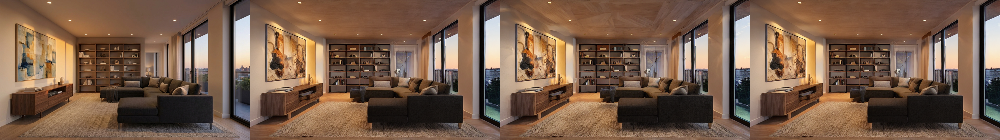

In [8]:
best = "Canny"   # change to the control type that won above
room = load_room(images[0]); orig = np.array(room)
control = control_makers[best](room)
pipe = pipes[best]

def run(label, steps=STEPS):
    out, sec, mem = generate(pipe, room, control, steps=steps)
    return {"setting": label, "Sec/image": sec, "Peak GPU GB": mem,
            "Mean ΔE ↓": mean_delta_e(orig, np.array(out)),
            "CLIP gain ↑": clip_score(out) - clip_score(room)}, out

speed_rows, outs = [], []
r, o = run("Baseline (25 steps)");        speed_rows.append(r); outs.append(o)
r, o = run("Fewer steps (15)", steps=15); speed_rows.append(r); outs.append(o)
pipe.enable_attention_slicing()
r, o = run("Attention slicing");          speed_rows.append(r); outs.append(o)
pipe.disable_attention_slicing()

speed = pd.DataFrame(speed_rows).round(3)
display(speed)
show_row([room] + outs)   # original | baseline | 15 steps | attention slicing

What I saw.

- **15 steps** was 33% faster (3.8 s vs 5.7 s per image), and quality stayed almost the same (mean ΔE 7.9 vs 7.8).
- **Attention slicing** saved no memory (6.53 GB in both cases) and was 47% slower. PyTorch 2 already uses a memory-efficient attention (SDPA), so slicing only helps on smaller GPUs or larger images. A good reminder to measure an optimisation instead of assuming it helps.

*Note: peak memory includes all models loaded in this notebook (three ControlNets, the depth model and CLIP), so it is higher than a single pipeline would need. Speed results are from one room.*

## 9. Download the results

In [10]:
# save the control maps (original | Canny | MLSD | Depth) for the first room
room = load_room(images[0])
maps = [room] + [make(room) for make in control_makers.values()]
grid = Image.new("RGB", (W * 4, H))
for i, im in enumerate(maps):
    grid.paste(im.resize((W, H)), (i * W, 0))
grid.save("exp2_control_maps.jpg", quality=90)

# save the speed comparison (original | baseline | 15 steps | attention slicing)
grid = Image.new("RGB", (W * 4, H))
for i, im in enumerate([load_room(images[0])] + outs):
    grid.paste(im.resize((W, H)), (i * W, 0))
grid.save("exp2_speed_comparison.jpg", quality=90)

In [11]:
speed.to_csv("exp2_speed.csv", index=False)
df.to_csv("exp2_metrics.csv", index=False)
!zip -q exp2_results.zip exp2_*.jpg exp2_*.csv
files.download("exp2_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>